# 04 - PCA and K-Means

This optional notebook groups similar people without using the diabetes target. PCA makes the result possible to plot in two dimensions.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
data = pd.read_csv("../dataset/diabetes.csv")

# Clustering has no target column, so we remove diabetes.
X = data.drop(columns="diabetes")
X = pd.get_dummies(X, columns=["gender", "smoking_history"], dtype=int)
X.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,1,0,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,1,0,0,1,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,0,1,0,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,1,0,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,0,1,0,0,1,0,0,0,0


In [3]:
# Scaling gives every feature a fair chance to affect the distance calculation.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# PCA reduces all features to two columns that we can plot.
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Variance explained by two PCA components: {pca.explained_variance_ratio_.sum():.2%}")

Variance explained by two PCA components: 27.54%


In [5]:
# Ask K-Means to place people into three groups.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

pca_data = pd.DataFrame(X_pca, columns=["PCA 1", "PCA 2"])
pca_data["Cluster"] = clusters
pca_data.head()

,PCA 1,PCA 2,Cluster
0,2.351444,1.254088,0
1,0.054375,-1.316961,0
2,-0.707604,0.956356,1
3,0.570227,-0.821800,0
4,0.105679,3.893638,1


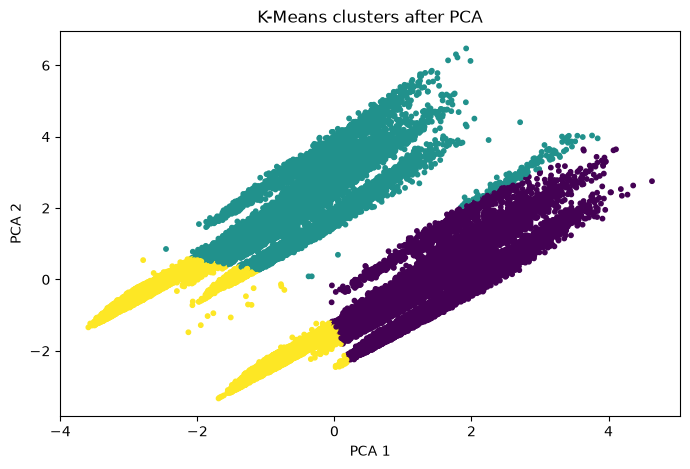

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(pca_data["PCA 1"], pca_data["PCA 2"], c=pca_data["Cluster"], cmap="viridis", s=10)
plt.title("K-Means clusters after PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()